# Task 4 – Lettura del sistema, fattorizzazione di Cholesky e soluzione

Questo notebook legge `A.txt` e `rhs.txt` prodotti da `task3`, costruisce la matrice sparsa in formato **CSC**, calcola la fattorizzazione di Cholesky $-A = LL^T$ e risolve il sistema $Au = b$ con due sistemi triangolari.

**Prerequisiti.** Gli eseguibili `task1`, `task2` e `task3` devono essere compilati nella stessa cartella del notebook. Il notebook li lancia da solo per generare i file, così ogni esperimento è riproducibile partendo solo da $N$.

In [13]:
import subprocess   # per lanciare task1, task2, task3 dal notebook
import time         # per misurare i tempi

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix, csc_matrix
from scipy.sparse.linalg import spsolve_triangular
from sksparse.cholmod import cholesky

## 1. Generazione dei file

La funzione `genera(N, scelta)` esegue la catena dei tre programmi C++:
`task1 N` → `coords.txt`, `connectivity.txt`; `task2` → `ordering.txt`; `task3 scelta` → `A.txt`, `rhs.txt`.

`check=True` fa sì che, se uno dei programmi termina con un errore (valore di ritorno diverso da 0), il notebook si fermi con un'eccezione invece di proseguire con file vecchi o incompleti.

In [14]:
def genera(N, scelta):
    # scelta: "naturale" oppure "riordinato"
    subprocess.run(["./task1", str(N)], check=True, capture_output=True)
    subprocess.run(["./task2"], check=True, capture_output=True)
    subprocess.run(["./task3", scelta], check=True, capture_output=True)

## 2. Lettura della matrice in formato CSC

`A.txt` contiene una tripla `r c valore` per ogni entrata non nulla: è il formato sparso **COO** (*coordinate*). SciPy lo legge direttamente con `coo_matrix((valori, (righe, colonne)))`, e poi lo convertiamo in **CSC** (*compressed sparse column*), il formato richiesto da CHOLMOD.

**Perché CSC.** In COO ogni entrata ha tre numeri; in CSC le entrate sono ordinate per colonna, si memorizzano solo i valori e gli indici di riga, più un vettore di $n+1$ puntatori che dice dove inizia ogni colonna. Occupa meno memoria e permette di accedere a una colonna in tempo proporzionale ai suoi non zeri, che è quello che serve alla fattorizzazione.

**Lettura veloce.** `np.fromfile(..., sep=" ")` legge tutti i numeri del file in un colpo solo (spazi e a capo fanno da separatori): con $N = 1024$ il file ha più di 5 milioni di righe, e un ciclo Python riga per riga sarebbe molto più lento. Con `reshape(-1, 3)` rimettiamo i numeri in righe da tre.

In [15]:
def leggi_sistema():
    dati = np.fromfile("A.txt", sep=" ").reshape(-1, 3)
    righe = dati[:, 0].astype(int)
    colonne = dati[:, 1].astype(int)
    valori = dati[:, 2]

    b = np.fromfile("rhs.txt", sep=" ")
    n = len(b)   # numero di incognite, N^2

    A = coo_matrix((valori, (righe, colonne)), shape=(n, n)).tocsc()
    return A, b

## 3. Fattorizzazione di Cholesky

$A$ è simmetrica e **definita negativa**, quindi non ammette la fattorizzazione di Cholesky; $-A$ invece è simmetrica definita positiva, e si può scrivere $-A = LL^T$ con $L$ triangolare inferiore.

Usiamo la funzione data nel testo del progetto. L'opzione `order="natural"` dice a CHOLMOD di **non riordinare** la matrice per conto suo: vogliamo misurare l'effetto del *nostro* riordinamento, quindi la libreria deve usare l'ordine delle incognite così come lo riceve.

**Nota sulla versione.** La funzione del testo usa `factor[0]` come $L$. Con `scikit-sparse` 0.5.0, però, `cholesky` restituisce una tupla $(R, p)$ in cui $R$ è triangolare **superiore** con $-A = R^TR$, e $p$ è la permutazione applicata. Ce ne siamo accorti perché il residuo veniva circa 1 invece di $10^{-14}$: verificando, $\|R^TR + A\|$ era dell'ordine di $10^{-14}$, mentre $\|RR^T + A\|$ era circa 13. Quindi prendiamo $L = R^T$, e controlliamo che $p$ sia l'identità, cioè che CHOLMOD non abbia applicato un suo riordinamento.

In [16]:
def my_cholesky(A):
    # scikit-sparse 0.5.0 restituisce una tupla (R, p):
    #   R e' triangolare SUPERIORE con A = R^T R (verificato: errore ~1e-14),
    #   p e' la permutazione applicata, che con order="natural" e' l'identita'.
    # Il fattore triangolare inferiore richiesto e' quindi L = R^T.
    R, p = cholesky(A, order="natural")
    assert np.array_equal(p, np.arange(A.shape[0])), "CHOLMOD ha riordinato la matrice"
    return csc_matrix(R.T)

## 4. Soluzione del sistema

Da $Au = b$ si ha $-Au = -b$, cioè $LL^Tu = -b$. Si risolve in due passi:

1. $Ly = -b$ (sostituzione in avanti, $L$ triangolare inferiore);
2. $L^Tu = y$ (sostituzione all'indietro, $L^T$ triangolare superiore).

Ognuno costa un tempo proporzionale ai non zeri di $L$: per questo un fattore $L$ più sparso rende più veloce anche la soluzione, oltre alla fattorizzazione.

`spsolve_triangular` lavora sul formato **CSR** (per righe), perché la sostituzione procede riga per riga: convertiamo prima, altrimenti SciPy lo farebbe da solo con un avviso.

Come controllo calcoliamo il **residuo relativo** $\|Au - b\| / \|b\|$, che deve essere dell'ordine della precisione di macchina (circa $10^{-15}$–$10^{-12}$).

In [17]:
def risolvi(A, b):
    t0 = time.perf_counter()
    L = my_cholesky(-A)
    t1 = time.perf_counter()

    y = spsolve_triangular(L.tocsr(), -b, lower=True)
    u = spsolve_triangular(L.T.tocsr(), y, lower=False)
    t2 = time.perf_counter()

    residuo = np.linalg.norm(A @ u - b) / np.linalg.norm(b)
    return u, L, t1 - t0, t2 - t1, residuo

## 5. Ritorno all'ordine naturale

Se il sistema è stato costruito con il riordinamento, l'incognita $m$ corrisponde al nodo $n$ dato dalla riga `m n` di `ordering.txt`. Per disegnare la soluzione sulla griglia rimettiamo i valori nell'ordine naturale: `u_nat[n] = u[m]`.

Nell'ordine naturale il nodo $n = (j-1)N + (i-1)$ sta in posizione $(i, j)$, quindi `u_nat.reshape(N, N)` dà una matrice in cui la riga è $j-1$ e la colonna è $i-1$: esattamente l'immagine della piastra, con $y$ verso l'alto se si usa `origin="lower"`.

In [18]:
def in_ordine_naturale(u, scelta):
    if scelta == "naturale":
        return u
    ordine = np.fromfile("ordering.txt", sep=" ").reshape(-1, 2).astype(int)
    u_nat = np.empty_like(u)
    u_nat[ordine[:, 1]] = u[ordine[:, 0]]
    return u_nat

## 6. Prova con N = 32

Risolviamo lo stesso problema con i due ordinamenti. Ci aspettiamo che:

- il residuo sia piccolo in entrambi i casi;
- le due soluzioni, riportate all'ordine naturale, coincidano (il riordinamento cambia *come* si risolve, non *cosa*);
- il fattore $L$ abbia meno non zeri con il riordinamento.

In [19]:
N = 32
soluzioni = {}

for scelta in ["naturale", "riordinato"]:
    genera(N, scelta)
    A, b = leggi_sistema()
    u, L, t_fatt, t_sol, res = risolvi(A, b)
    soluzioni[scelta] = in_ordine_naturale(u, scelta)
    print(f"{scelta:>10}: nnz(A) = {A.nnz}, nnz(L) = {L.nnz}, "
          f"fattorizzazione {t_fatt:.4f} s, soluzione {t_sol:.4f} s, "
          f"residuo {res:.2e}")

diff = np.max(np.abs(soluzioni["naturale"] - soluzioni["riordinato"]))
print(f"Massima differenza tra le due soluzioni: {diff:.2e}")

  naturale: nnz(A) = 4992, nnz(L) = 32799, fattorizzazione 0.0018 s, soluzione 0.0034 s, residuo 1.77e-14
riordinato: nnz(A) = 4992, nnz(L) = 16033, fattorizzazione 0.0008 s, soluzione 0.0017 s, residuo 1.79e-14
Massima differenza tra le due soluzioni: 6.66e-15


In [ ]:
## 7. Grafico della soluzione

La sorgente $f(x, y) = e^{-10(x^2+y^2)}$ è più intensa nell'angolo $(0, 0)$, ma lì il bordo è tenuto a temperatura $u_0 = 0$ e disperde il calore. 
Il massimo della temperatura si trova quindi un po' all'interno, intorno a $(0.2, 0.2)$: 
è il compromesso tra la sorgente, che spinge verso l'angolo, e il bordo freddo, che abbassa la temperatura vicino ai lati. 
Lontano dall'angolo la sorgente è quasi nulla e $u$ decresce verso 0.

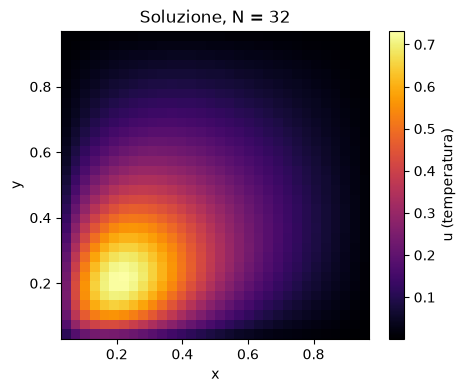

In [20]:
h = 1 / (N + 1)
U = soluzioni["riordinato"].reshape(N, N)   # U[j-1, i-1]

plt.figure(figsize=(5, 4))
plt.imshow(U, origin="lower", extent=[h, 1 - h, h, 1 - h], cmap="inferno")
plt.colorbar(label="u (temperatura)")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Soluzione, N = {N}")
plt.show()